# 🎬 Movie Dataset – Data Cleaning & Analysis

This project focuses on cleaning, analyzing, and visualizing a movie dataset using Python, Pandas, Matplotlib, and Seaborn.

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load Dataset

In [31]:
df =pd.read_csv("movie dataset.csv")

## 3. Handle Missing Values

In [32]:
# check missing values
# cheking missing values using isnull() and sum() functions
print(df.isnull().sum())

Movie_ID        0
Movie_Title     0
Genre           4
Release_Year    0
IMDb_Rating     6
Runtime_Min     5
Director        3
dtype: int64


In [33]:
#handle missing values
#manage missing values by filling genre and director with "Unknown" and filling IMDb_Rating and Runtime_Min with median values
df["Genre"] = df["Genre"].fillna("Unknown")
df["Director"] = df["Director"].fillna("Unknown")
df["IMDb_Rating"] = df["IMDb_Rating"].fillna(df["IMDb_Rating"].median())
df["Runtime_Min"] = df["Runtime_Min"].fillna(df["Runtime_Min"].median())
print(df.isnull().sum())

Movie_ID        0
Movie_Title     0
Genre           0
Release_Year    0
IMDb_Rating     0
Runtime_Min     0
Director        0
dtype: int64


## 5. Rename Columns

In [34]:
# Rename column for clarity
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(df.columns)


Index(['movie_id', 'movie_title', 'genre', 'release_year', 'imdb_rating',
       'runtime_min', 'director'],
      dtype='str')


## 4. Remove Duplicate Rows

In [35]:
#manage duplicate rows
print("Duplicate rows before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicate rows after:", df.duplicated().sum())


Duplicate rows before: 1
Duplicate rows after: 0


## 6. Movies Released Before 2000

In [36]:
# movies released before the year 2000
movies_before_2000 = df[df["release_year"] < 2000][["movie_title", "release_year", "genre", "director", "imdb_rating", "runtime_min"]]
print("Movies released before the year 2000:")
print(movies_before_2000)

Movies released before the year 2000:
                  movie_title  release_year     genre              director  \
0    The Shawshank Redemption          1994     Drama        Frank Darabont   
1               The Godfather          1972     Crime  Francis Ford Coppola   
3       The Godfather Part II          1974     Crime  Francis Ford Coppola   
4                12 Angry Men          1957     Drama          Sidney Lumet   
5            Schindler's List          1993     Drama      Steven Spielberg   
..                        ...           ...       ...                   ...   
97                Stand by Me          1986     Drama            Rob Reiner   
98         Dead Poets Society          1989     Drama            Peter Weir   
117               Movie Night          1997    Comedy           Alex Carter   
118               City Lights          1931    Comedy       Charlie Chaplin   
119              The Fugitive          1993  Thriller          Andrew Davis   

     imdb_rat

## 7. Average Rating per Genre

In [37]:
 #Calculate average ratings per genre
avg_ratings_per_genre = df.groupby("genre")["imdb_rating"].mean()
print("Average ratings per genre:")
print(avg_ratings_per_genre)


Average ratings per genre:
genre
 action      9.000000
Action       8.290000
Adventure    8.200000
Animation    8.333333
Comedy       7.971429
Crime        8.516667
Drama        8.477273
Fantasy      6.500000
Horror       8.000000
Mystery      8.228571
Romance      8.100000
Sci-Fi       7.900000
Sport        8.150000
Thriller     8.325000
Unknown      8.250000
War          8.340000
Western      8.600000
sci-fi       8.700000
Name: imdb_rating, dtype: float64


TOP 5 highest rated movies 

In [38]:
# the top 5 highest-rated movies
top_5_highest_rated_movies = df.nlargest(5, "imdb_rating")[["movie_title", "imdb_rating"]]
print("Top 5 highest-rated movies:")
print(top_5_highest_rated_movies)

Top 5 highest-rated movies:
                movie_title  imdb_rating
0  The Shawshank Redemption          9.3
1             The Godfather          9.2
2           The Dark Knight          9.0
3     The Godfather Part II          9.0
4              12 Angry Men          9.0


## 8. Count of Movies per Genre

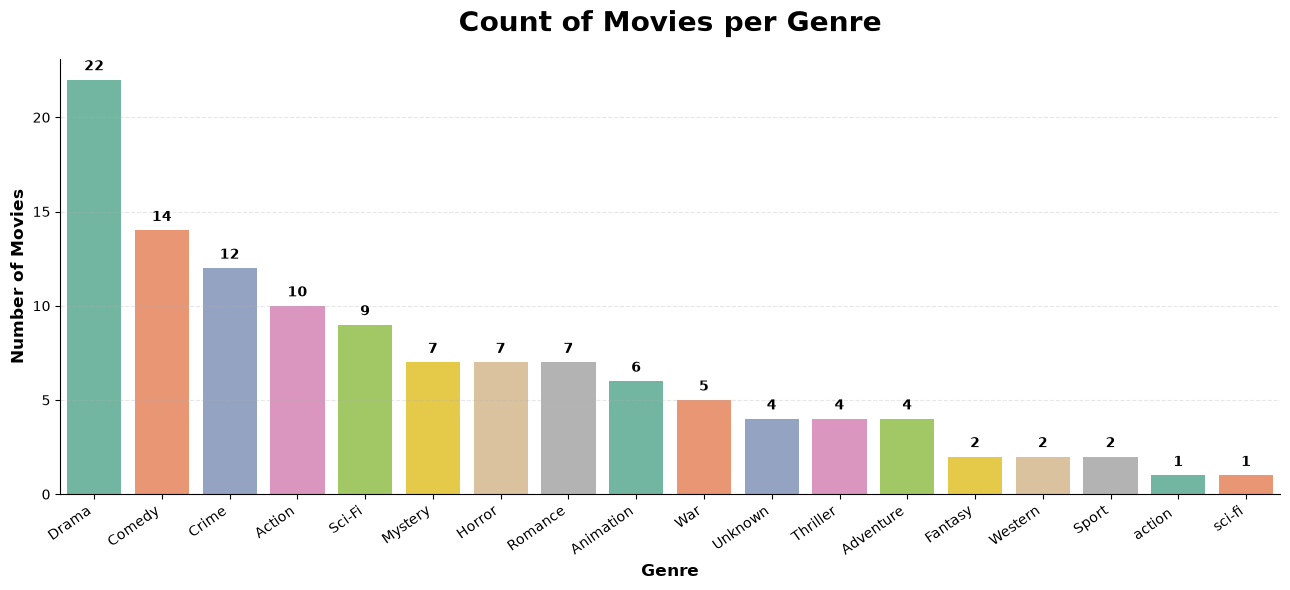

In [39]:
#Create a bar chart showing the count of movies per genre
genre_counts = df["genre"].value_counts()

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    x=genre_counts.index,
    y=genre_counts.values,
    hue=genre_counts.index,
    palette="Set2",
    legend=False
)

plt.title(
    "Count of Movies per Genre",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Genre", fontsize=12, fontweight="bold")
plt.ylabel("Number of Movies", fontsize=12, fontweight="bold")

# Rotate genre names
plt.xticks(rotation=35, ha="right")

# Light grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

# Add values on top of bars
for i, value in enumerate(genre_counts.values):
    ax.text(
        i,
        value + 0.5,
        str(value),
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

# Clean borders
sns.despine()

plt.tight_layout()
plt.show()

## 7. Average Rating by Genre

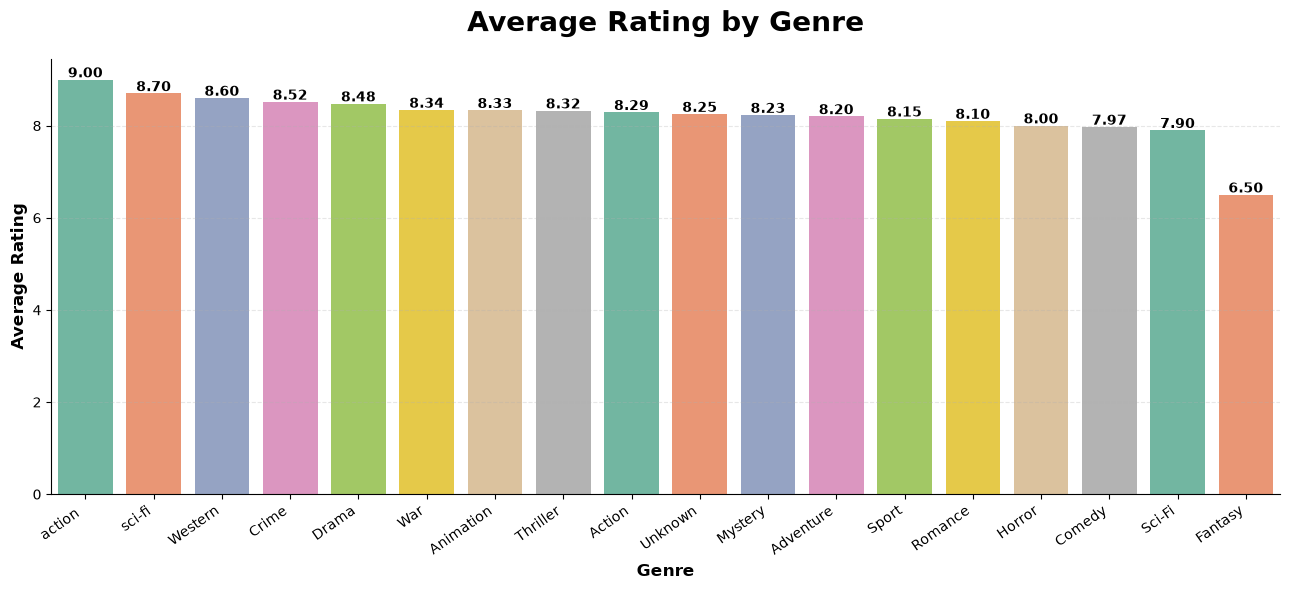

In [40]:
# average rating by genre 
avg_rating_by_genre = df.groupby("genre")["imdb_rating"].mean().sort_values(ascending=False)

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    x=avg_rating_by_genre.index,
    y=avg_rating_by_genre.values,
    hue=avg_rating_by_genre.index,
    palette="Set2",
    legend=False
)

# Title
plt.title(
    "Average Rating by Genre",
    fontsize=20,
    fontweight="bold",
    pad=20
)

# Labels
plt.xlabel("Genre", fontsize=12, fontweight="bold")
plt.ylabel("Average Rating", fontsize=12, fontweight="bold")

# Rotate genre names
plt.xticks(rotation=35, ha="right")

# Light horizontal grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

# Remove unnecessary borders
sns.despine()

# Add exact values on top of bars
for i, value in enumerate(avg_rating_by_genre.values):
    ax.text(
        i,
        value + 0.05,
        f"{value:.2f}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()